,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


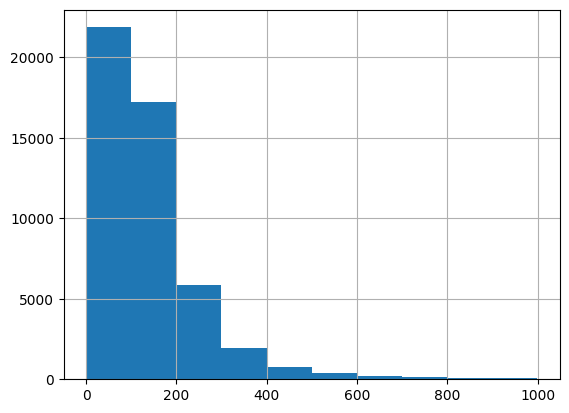

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

df = pd.read_csv("AB_NYC_2019.csv")
df = df[df['price'] < 1000]
df.price.hist()
df

In [2]:
features = df[['price','minimum_nights','number_of_reviews','availability_365']].dropna()

In [3]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

In [4]:
kmeans = KMeans(n_clusters=5, random_state=42)  # Adjust clusters as needed
df['cluster'] = kmeans.fit_predict(scaled_features)

<Axes: xlabel='latitude', ylabel='longitude'>

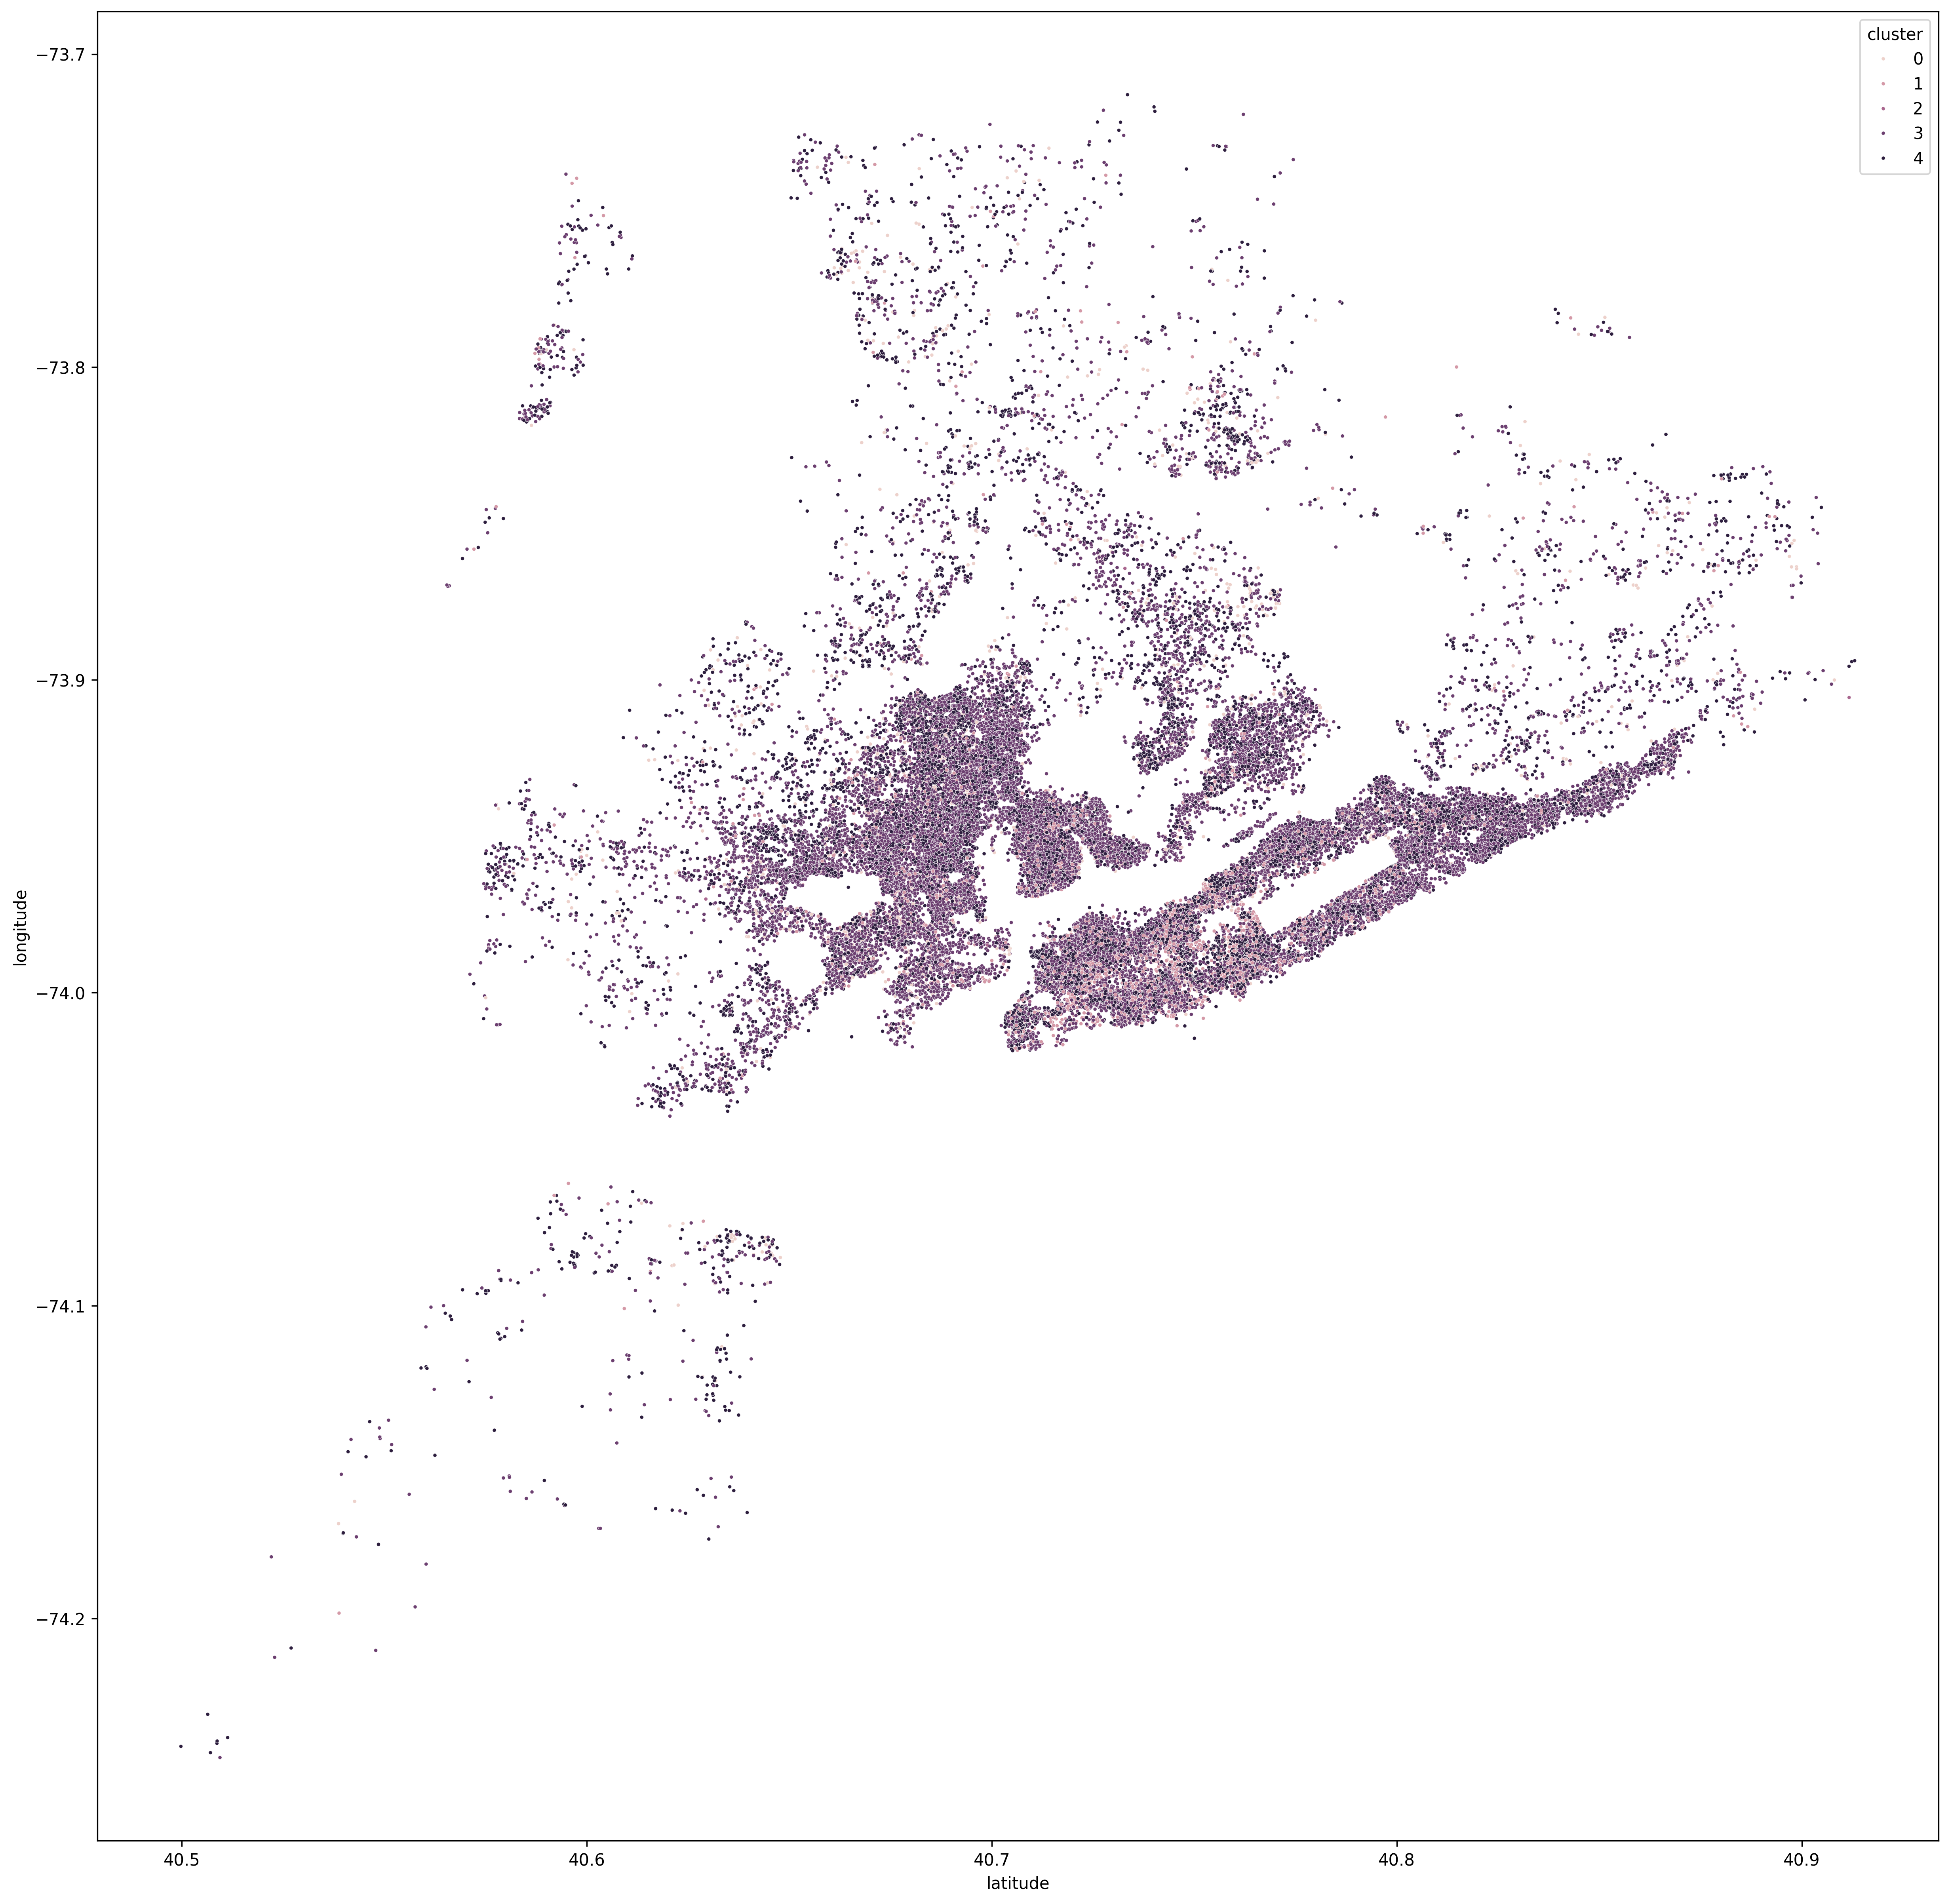

In [5]:
plt.figure(figsize=(20,20),dpi=300)
sns.scatterplot(data=df,x='latitude',y='longitude',hue='cluster',s=5)

<Axes: xlabel='price', ylabel='Density'>

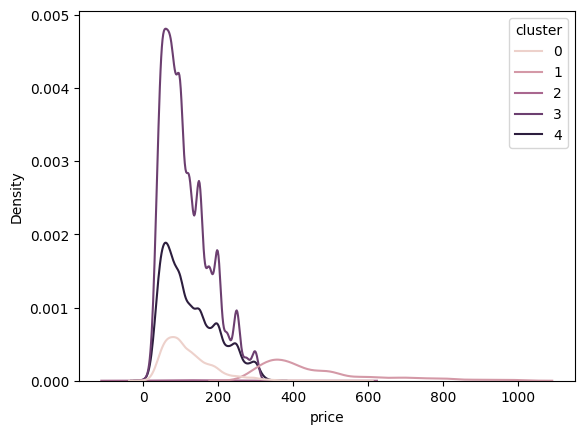

In [6]:
sns.kdeplot(data=df,x='price',hue='cluster')

In [7]:
high_price_df = df[df['cluster'] == 1]

In [8]:
high_price_df['room_type'].value_counts()

room_type
Entire home/apt    2850
Private room        310
Shared room          20
Name: count, dtype: int64

<Figure size 6000x6000 with 0 Axes>

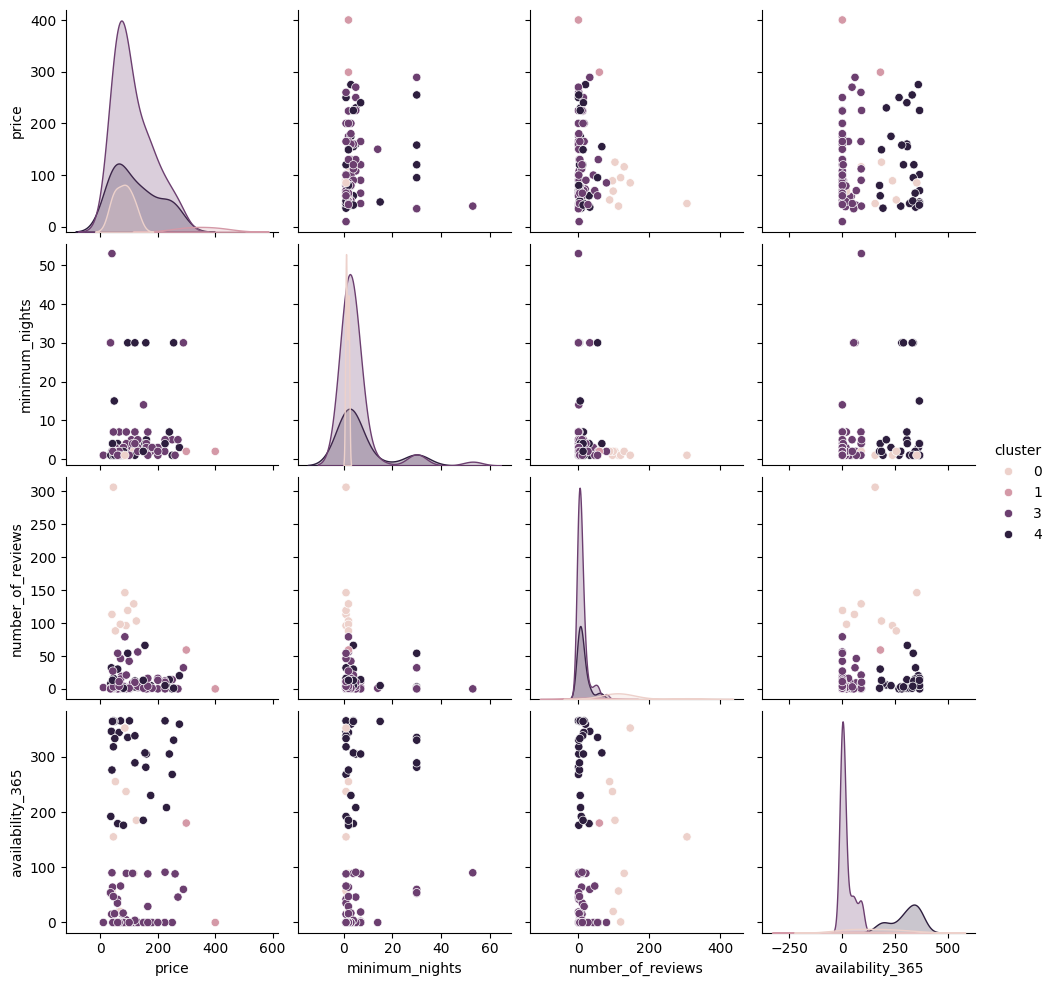

In [9]:
plt.figure(figsize=(20,20),dpi=300)
sns.pairplot(data=df.sample(100),vars=['price','minimum_nights','number_of_reviews','availability_365'],hue='cluster')

In [10]:
from sentence_transformers import SentenceTransformer
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

/opt/homebrew/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [11]:
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
df = pd.read_csv("AB_NYC_2019.csv")
embeddings = model.encode(df['name'].tolist())
df['embedding'] = list(embeddings)

In [12]:
df = df[df['price'] < 1000]

In [14]:
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
df = pd.read_csv("AB_NYC_2019.csv")
embeddings = model.encode(df['name'].tolist())
df['embedding'] = list(embeddings)
import numpy as np
random_sample = df.sample(1000)
embeddings_subset = random_sample['embedding']
embeddings_subset = np.array(embeddings_subset.to_list())

from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(embeddings_subset)

# Add t-SNE results to the DataFrame
random_sample['tsne_1'] = tsne_results[:, 0]
random_sample['tsne_2'] = tsne_results[:, 1]

In [15]:
X = np.hstack([pd.get_dummies(random_sample[['price','latitude','longitude','number_of_reviews','availability_365']]).values,embeddings_subset])
kmeans = KMeans(n_clusters=5, random_state=42)  # Adjust clusters as needed
random_sample['cluster'] = kmeans.fit_predict(X)

<Axes: xlabel='tsne_1', ylabel='tsne_2'>

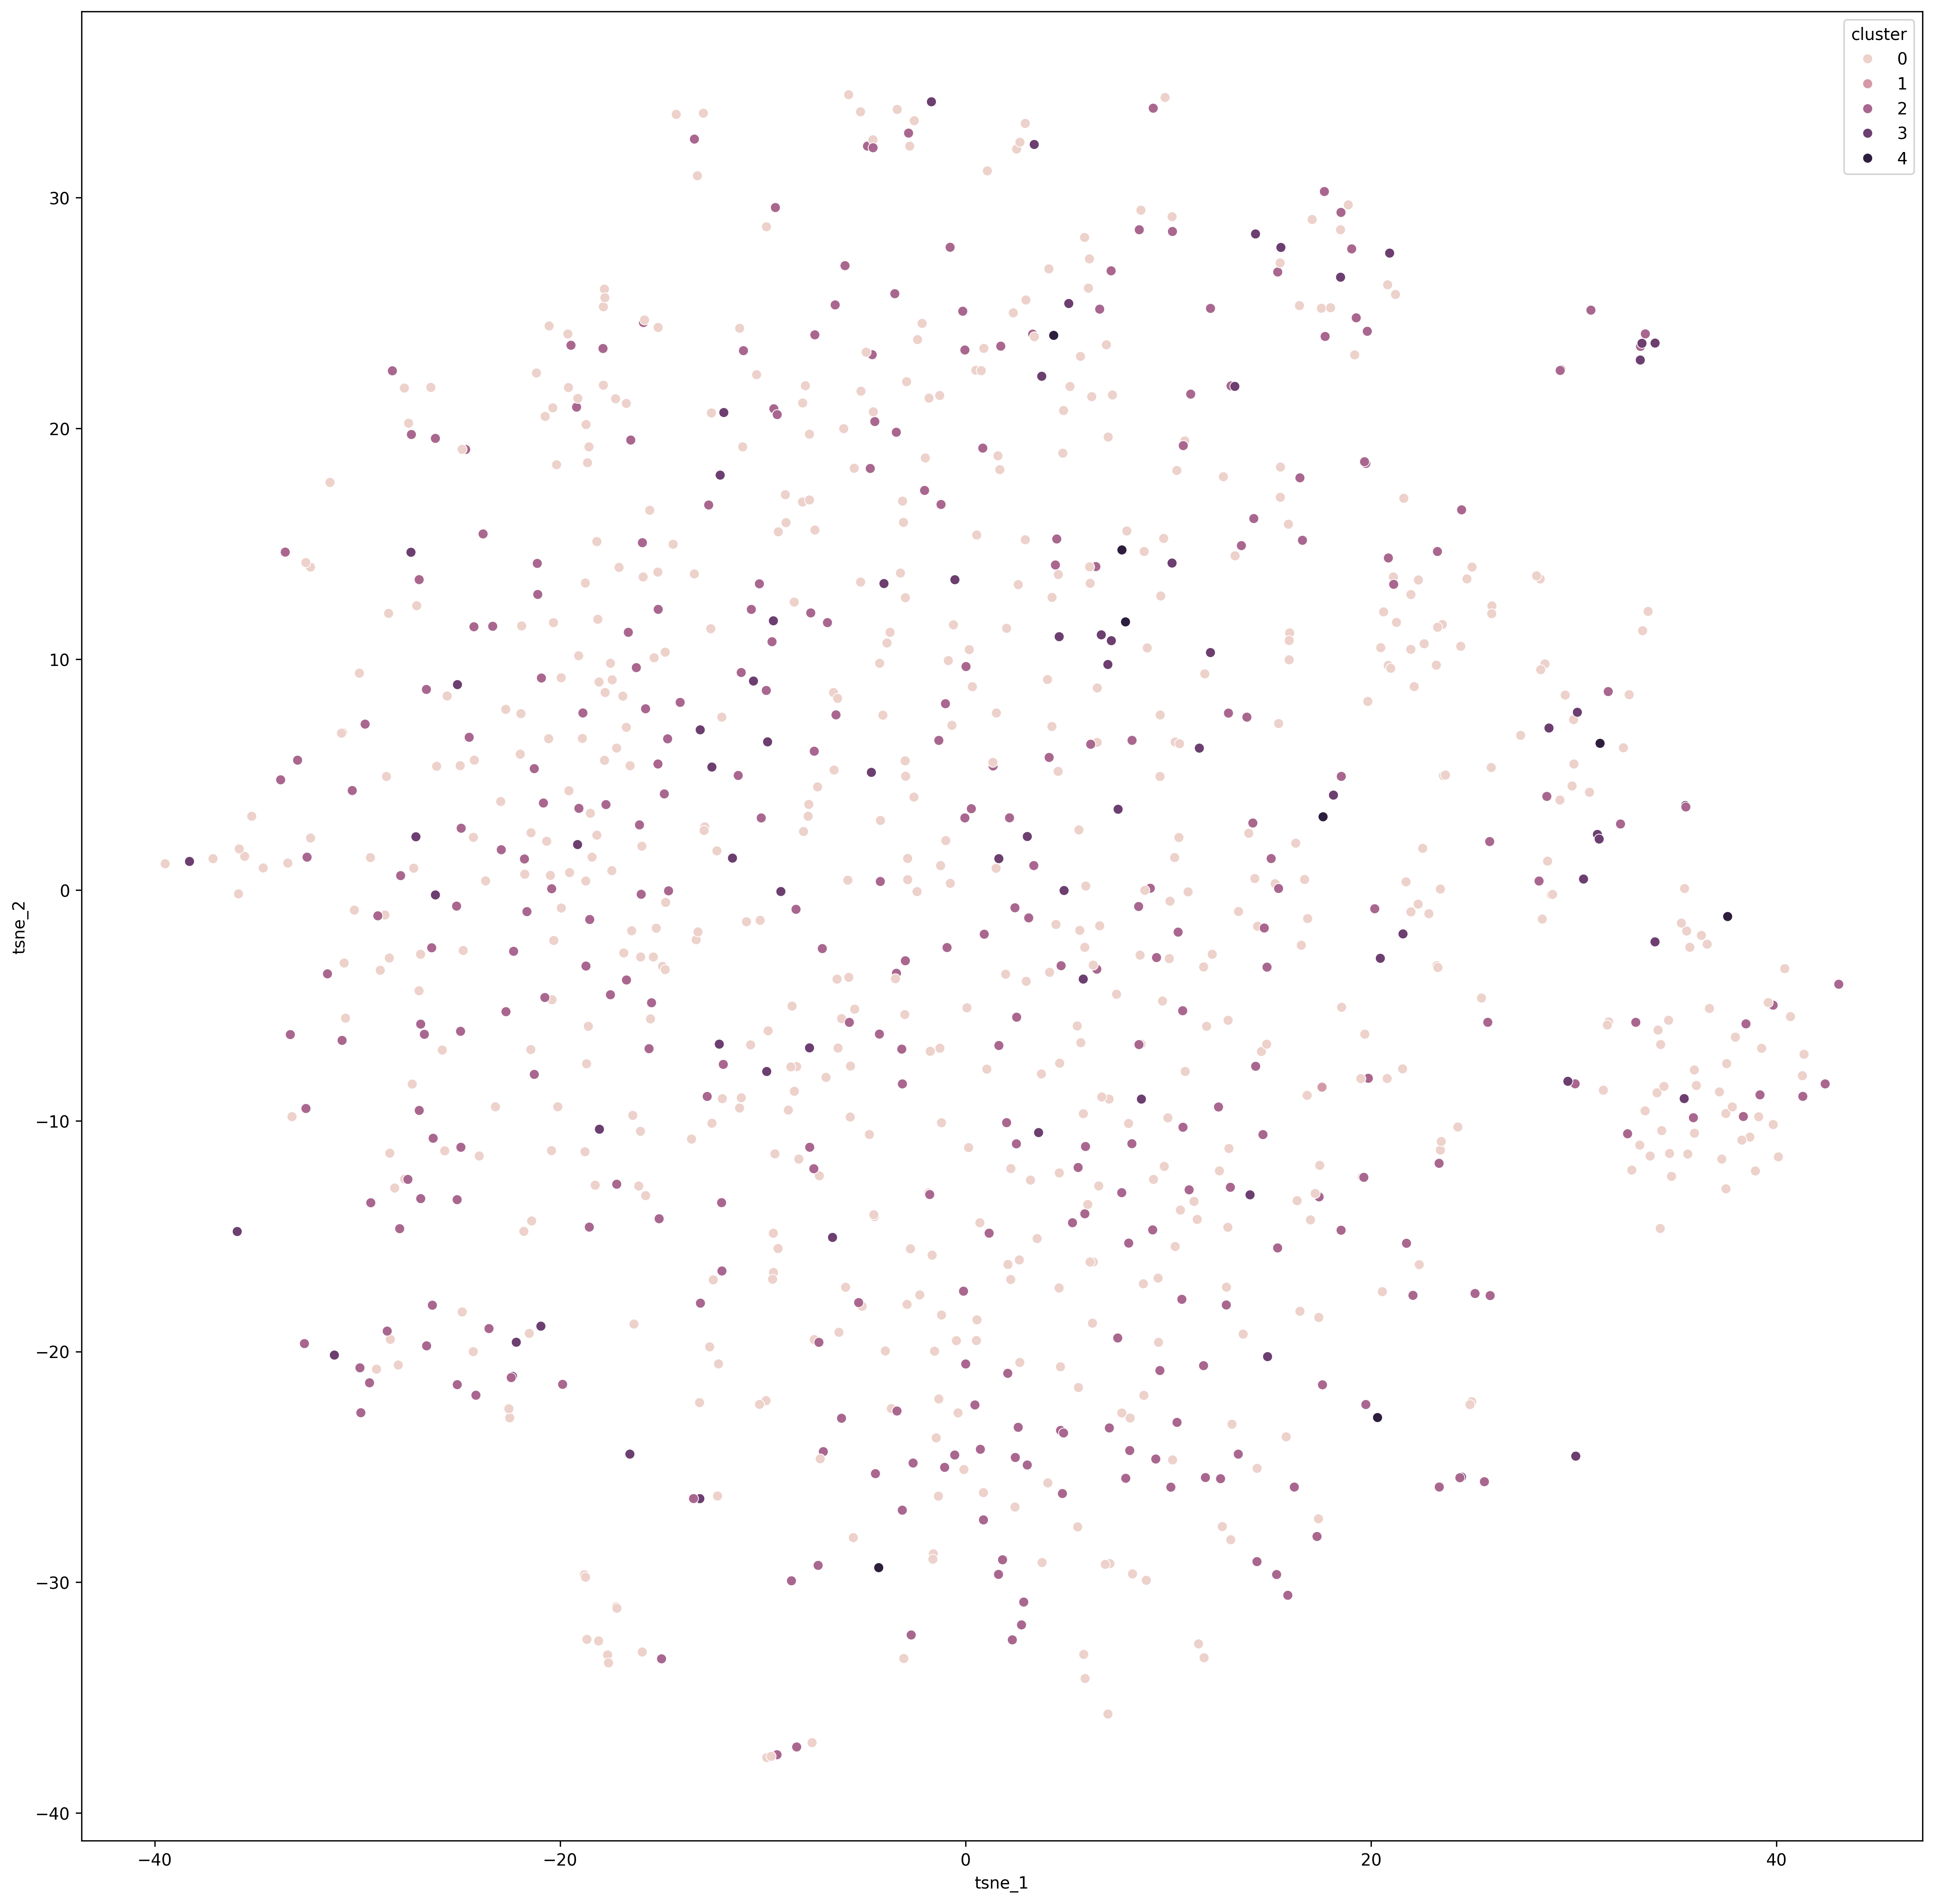

In [16]:
plt.figure(figsize=(20,20),dpi=300)
sns.scatterplot(data=random_sample,x='tsne_1',y='tsne_2',hue='cluster')

<Axes: xlabel='price'>

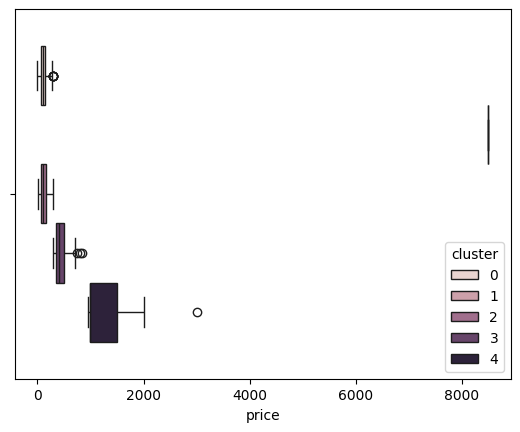

In [17]:
sns.boxplot(data=random_sample,x='price',hue='cluster')

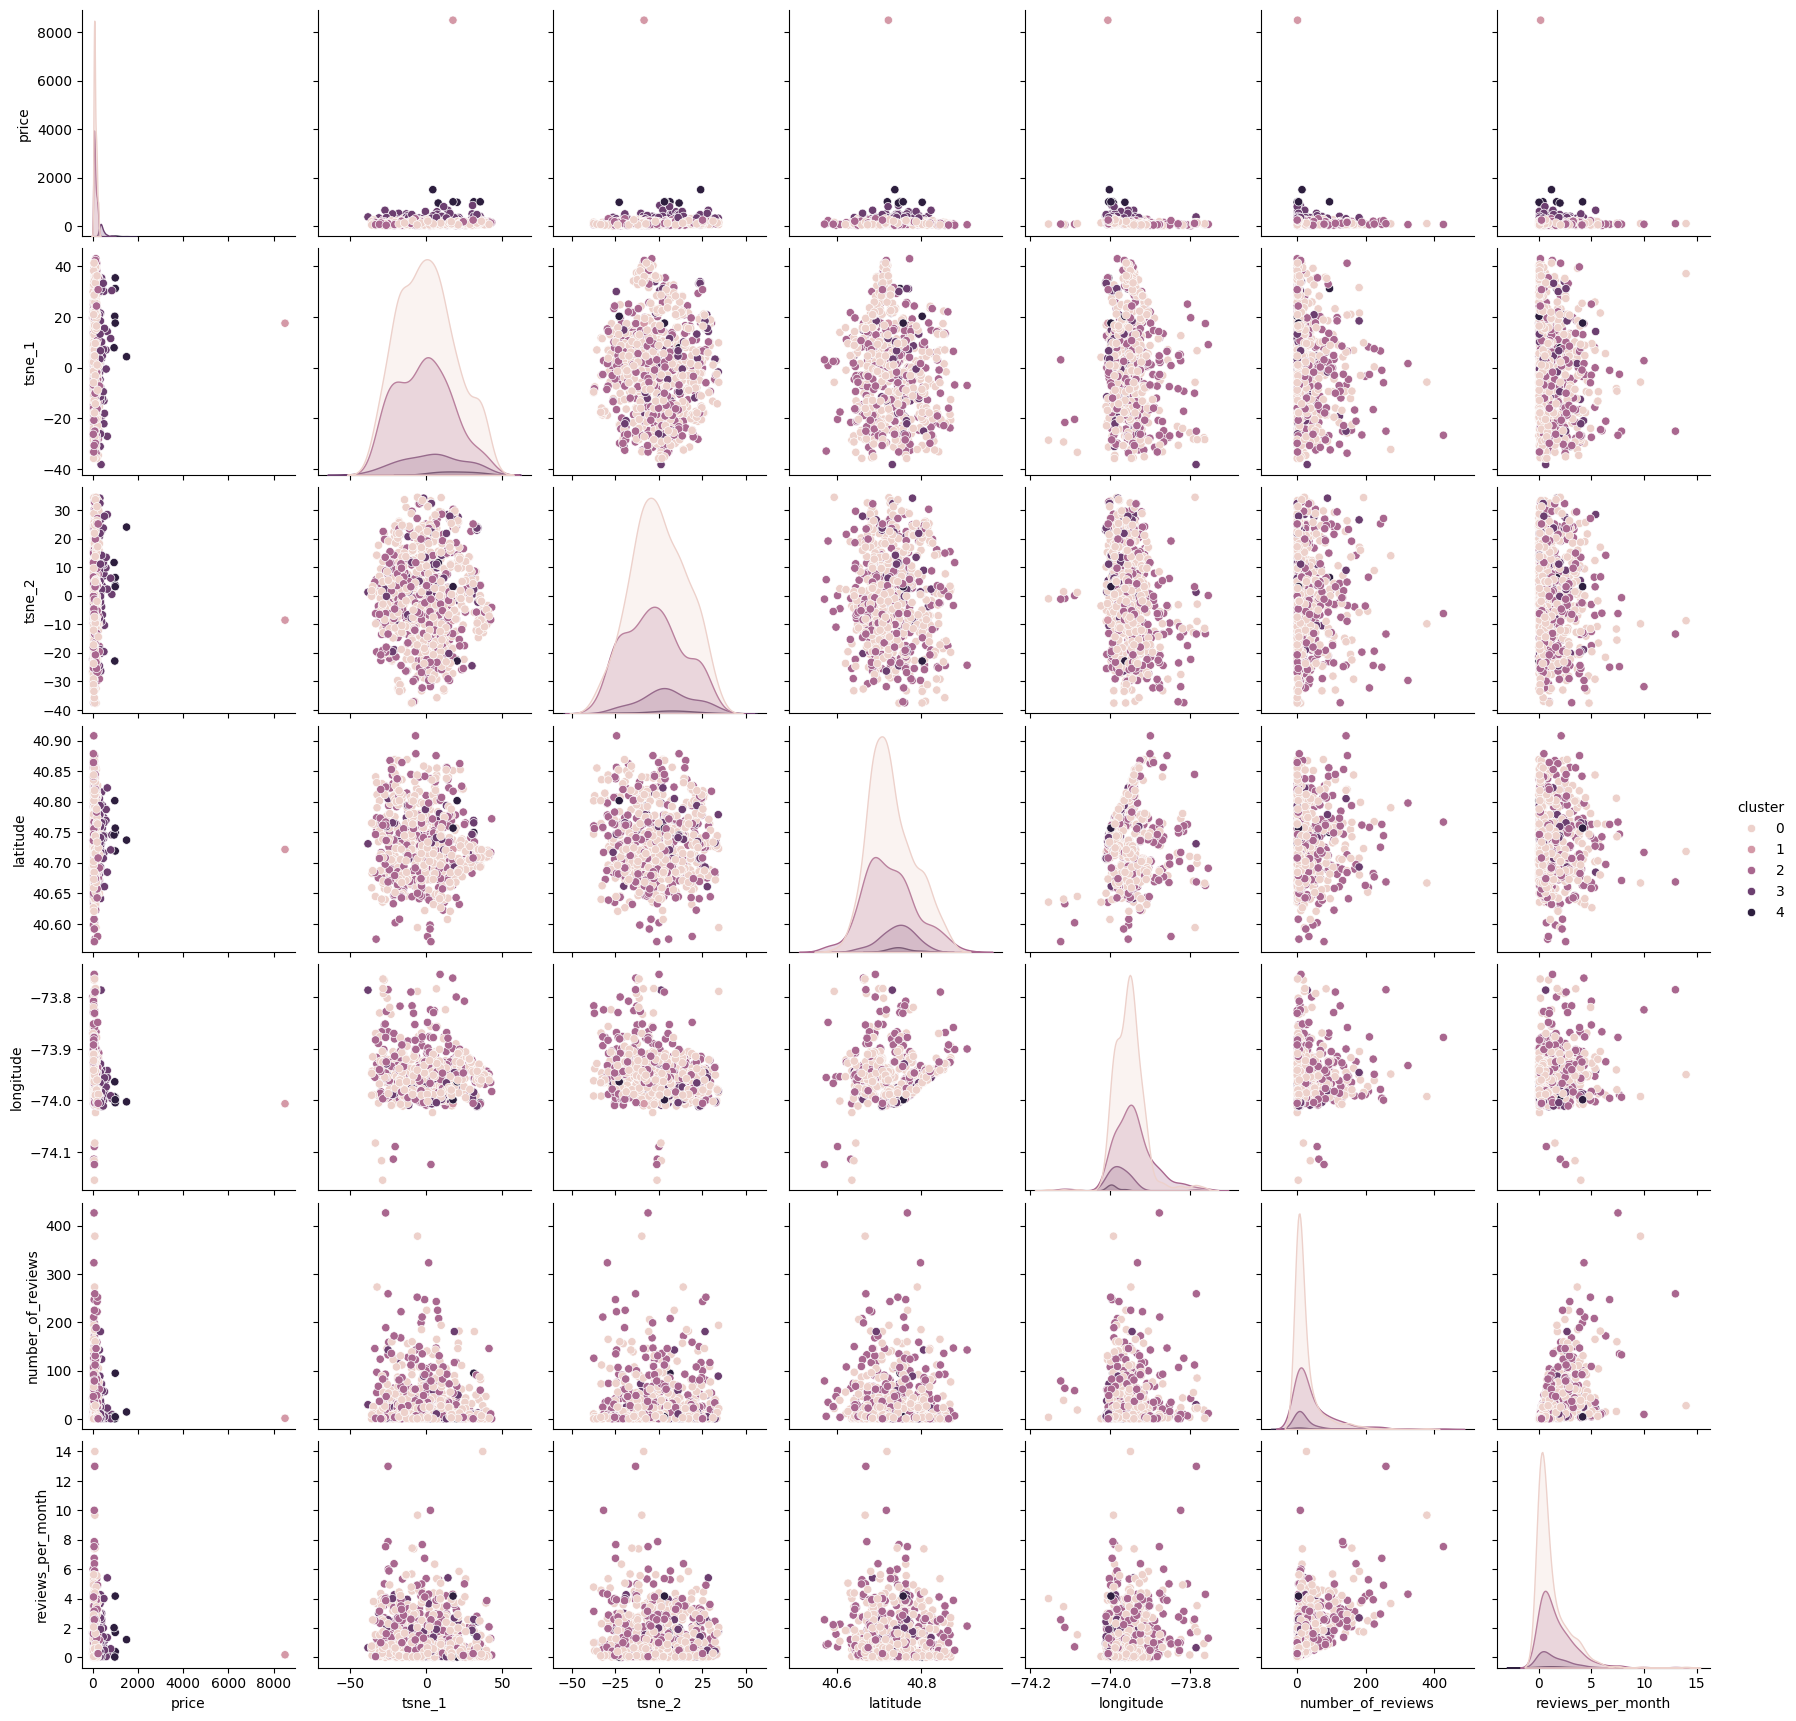

In [18]:
import seaborn as sns
# plt.figure(figsize=(20,20),dpi=300)
random_sample_clean = random_sample[['price','cluster','tsne_1','tsne_2','latitude','longitude','number_of_reviews','reviews_per_month']].dropna()
sns.pairplot(data=random_sample_clean, vars=['price','tsne_1','tsne_2','latitude','longitude','number_of_reviews','reviews_per_month'],hue='cluster')
plt.show()

In [19]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Convert embeddings to a NumPy array
X_text = np.array(df['embedding'].tolist())

# Example numeric features
# X_numeric = df[['price']].values

# Combine text embeddings with other features
X = np.hstack([X_text])
y = df['price']

X = X[:100]
y = y[:100]
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a Random Forest Regressor
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

Mean Squared Error: 4541.347825
-0.717709023617163


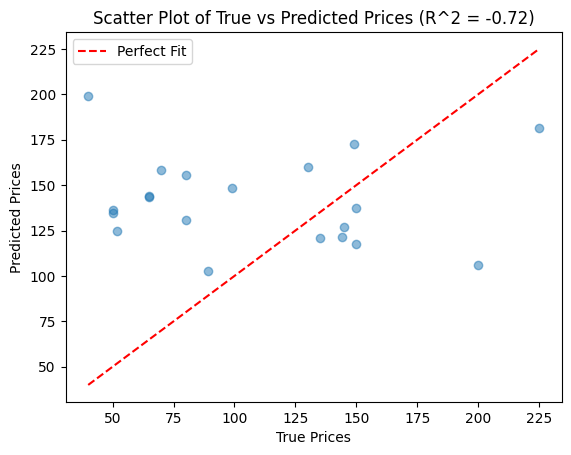

In [20]:
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error: {mse}')
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

# Calculate R^2 score
r2 = r2_score(y_test, y_pred)
print(r2)
# Scatter plot of true vs predicted prices
plt.scatter(y_test, y_pred, alpha=0.5)
plt.title(f'Scatter Plot of True vs Predicted Prices (R^2 = {r2:.2f})')
plt.xlabel('True Prices')
plt.ylabel('Predicted Prices')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--', label='Perfect Fit')
plt.legend()
plt.show()

In [21]:
random_sample

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,embedding,tsne_1,tsne_2,cluster
16695,13355833,Private Room in Williamsburg,5628991,Christian,Brooklyn,Williamsburg,40.71940,-73.96262,Private room,85,3,0,NaN,NaN,1,0,"[0.09587822, 0.0028377625, 0.020366944, 0.0087...",33.251076,-11.058500,0
21716,17458077,Studio Apartment in a Doorman Building,2610519,Michael,Manhattan,Flatiron District,40.74252,-73.99100,Entire home/apt,250,1,2,2017-03-27,0.07,1,0,"[0.045952402, 0.0118603185, -0.024134563, -0.0...",2.021356,11.338447,0
34001,26937970,3 BEDS -ROOM IN CONVERTED FACTORY LOFT -NEAR M...,35606248,Blake And Madia,Brooklyn,Bushwick,40.70458,-73.92753,Private room,95,2,23,2019-06-09,2.08,5,361,"[0.096324965, -0.039940268, -0.008678506, 0.02...",28.283722,0.387662,2
4247,2793834,Central Park beauty,14290739,Stanton,Manhattan,Upper West Side,40.79194,-73.96913,Entire home/apt,200,30,28,2018-01-15,0.45,3,0,"[0.080197476, -0.03451085, 0.06769859, -0.0113...",-10.603067,-6.712322,0
11259,8733472,20 mins to Manhattan Entire Studio,475986,Mary Beth,Queens,Kew Gardens,40.71065,-73.83015,Entire home/apt,100,1,14,2019-01-01,0.31,1,90,"[0.11854139, -0.04644469, 0.034403846, 0.00062...",-30.651346,-3.167343,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9646,7410868,Great spot in Lower East Side,5417646,EmiLy,Manhattan,Lower East Side,40.71546,-73.98960,Entire home/apt,120,4,3,2016-05-13,0.08,1,0,"[0.082796454, 0.06282989, 0.07440968, -0.00904...",-3.213861,13.733405,0
30504,23609407,Very small room near CUMC,176591085,Mike,Manhattan,Washington Heights,40.84389,-73.94127,Private room,45,1,1,2018-05-06,0.07,4,90,"[0.033540588, -0.03983035, -0.051595274, 0.031...",-5.918848,-17.214983,0
35828,28437669,Two-Story 2BR/2BA East Village Apartment!,3964276,Steve,Manhattan,East Village,40.72447,-73.98821,Entire home/apt,255,3,6,2018-12-30,0.65,1,0,"[0.05210628, 0.009570852, 0.008205637, 0.02323...",0.702879,-14.420019,0
34359,27248487,Cozy & Chic West Village One Bedroom Oasis,205227236,Anne,Manhattan,West Village,40.73394,-74.00175,Entire home/apt,200,2,3,2018-09-03,0.27,1,0,"[0.112452276, -0.117296875, -0.038926892, 0.00...",1.072970,31.159792,0


In [22]:
random_sample[(random_sample['tsne_1'] < -20) & (random_sample['tsne_1'] > -60) & ((random_sample['tsne_2'] > 50) & (random_sample['tsne_2'] < 75))]['neighbourhood_group'].value_counts()

Series([], Name: count, dtype: int64)

In [23]:
random_sample[(random_sample['tsne_1'] < -20) & (random_sample['tsne_1'] > -60) & ((random_sample['tsne_2'] > 50) & (random_sample['tsne_2'] < 75))]

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,embedding,tsne_1,tsne_2,cluster


<Axes: xlabel='tsne_1', ylabel='tsne_2'>

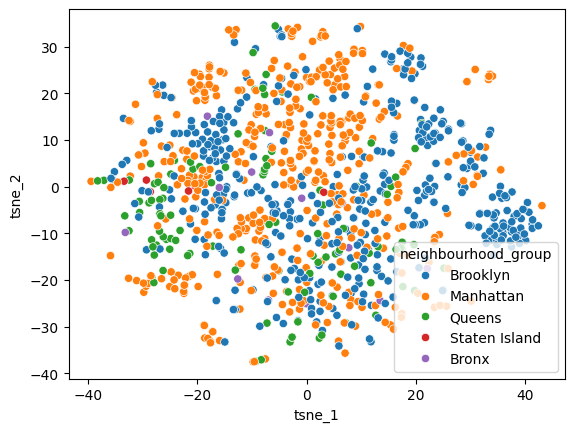

In [24]:
sns.scatterplot(data=random_sample,x='tsne_1',y='tsne_2',hue='neighbourhood_group')

Mean Squared Error: 5247.087644001736


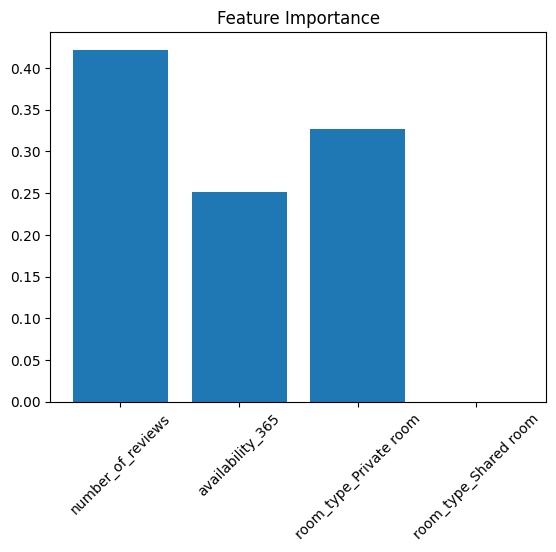

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# Select features and target variable
df = df.dropna(subset=['price', 'number_of_reviews', 'availability_365', 'room_type'])
X = pd.get_dummies(df[['number_of_reviews', 'availability_365', 'room_type']], drop_first=True)
y = df['price']

X = X[:100]
y = y[:100]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a Random Forest Regressor
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)

print(f'Mean Squared Error: {mse}')

# Feature Importance
importances = model.feature_importances_
plt.bar(X.columns, importances)
plt.title('Feature Importance')
plt.xticks(rotation=45)
plt.show()

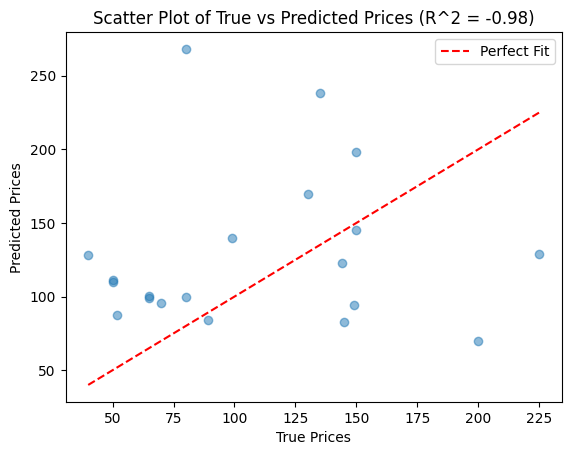

In [29]:
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

# Predict and evaluate
y_pred = model.predict(X_test)

# Calculate R^2 score
r2 = r2_score(y_test, y_pred)

# Scatter plot of true vs predicted prices
plt.scatter(y_test, y_pred, alpha=0.5)
plt.title(f'Scatter Plot of True vs Predicted Prices (R^2 = {r2:.2f})')
plt.xlabel('True Prices')
plt.ylabel('Predicted Prices')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--', label='Perfect Fit')
plt.legend()
plt.show()